## Quiz 2. Simulacion en Python

## Esteban Garcia Otalvaro
## CC.1001446658

**Nota:** no tenia el enunciado completo a la mano, asi que construi el modelo por analogia con el taller del ventilador (misma ecuacion de 2do orden), usando los valores que ya aparecian en tus comentarios. Si el enunciado real trae otros numeros, solo hay que cambiar los parametros marcados abajo.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import odeint
from scipy import signal

### Punto 1. Modelo y parametros

Se asume un modelo de un compartimento, analogo al del sistema respiratorio:

$$t_a\ddot c(t) + t_e\dot c(t) + \frac{1}{t_d}c(t) = D(t)$$

donde:
- $t_a$: tiempo de absorcion (equivalente a la inertancia $I$)
- $t_e$: tiempo de eliminacion (equivalente a la resistencia $R$)
- $t_d$: tiempo de distribucion (equivalente a la distensibilidad $C$)
- $D(t)$: tasa de dosificacion del farmaco (entrada del sistema)
- $c(t)$: concentracion del farmaco (salida del sistema)

In [2]:
# ---- Parametros paciente 1 (AJUSTAR segun enunciado real) ----
ta1, te1, td1 = 0.02, 12, 5      # parametros fisiologicos
c0_1 = 0.2                        # concentracion inicial c(0)

# ---- Parametros paciente 2 (AJUSTAR segun enunciado real) ----
ta2, te2, td2 = 0.03, 18, 6
c0_2 = 0.3

# Tiempo de simulacion (25 s)
t = np.linspace(0, 25, 3000)

### Punto 2. Senal de tasa de dosificacion D(t) para cada paciente

In [3]:
# Dosis (tasa de cambio de concentracion administrada) para cada paciente
def D1(t):
    return 15 * np.sin(2 * np.pi * 0.1 * t) + 0.2

def D2(t):
    return 20 * np.sin(2 * np.pi * 0.15 * t) + 0.3

tasa_cambio_paciente1 = D1(t)
tasa_cambio_paciente2 = D2(t)

### Punto 3. Grafica comparativa de la senal de dosificacion

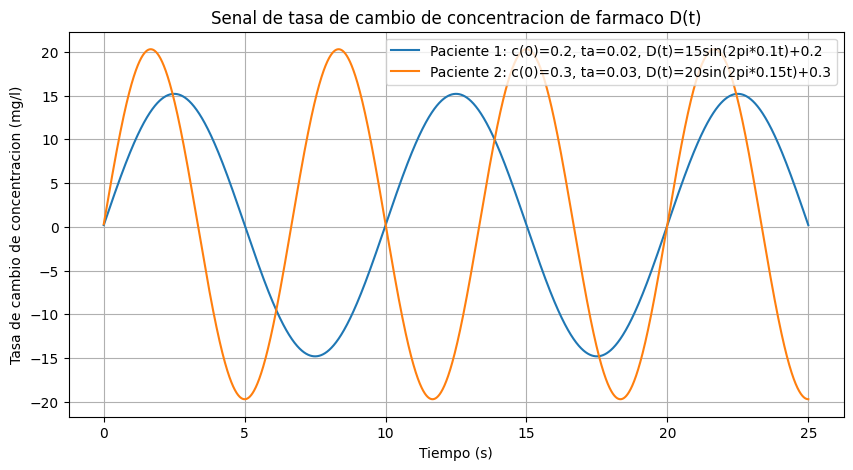

In [4]:
plt.figure(figsize=(10, 5))
plt.plot(t, tasa_cambio_paciente1, label='Paciente 1: c(0)=0.2, ta=0.02, D(t)=15sin(2pi*0.1t)+0.2')
plt.plot(t, tasa_cambio_paciente2, label='Paciente 2: c(0)=0.3, ta=0.03, D(t)=20sin(2pi*0.15t)+0.3')
plt.title('Senal de tasa de cambio de concentracion de farmaco D(t)')
plt.xlabel('Tiempo (s)')
plt.ylabel('Tasa de cambio de concentracion (mg/l)')
plt.legend()
plt.grid(True)
plt.show()

### Punto 4. Paciente con mayor tasa de concentracion al final de la prueba (t=25 s)

In [5]:
concentracion_final_paciente1 = tasa_cambio_paciente1[-1]
concentracion_final_paciente2 = tasa_cambio_paciente2[-1]

print(f"Tasa final paciente 1: {concentracion_final_paciente1:.4f} mg/l")
print(f"Tasa final paciente 2: {concentracion_final_paciente2:.4f} mg/l")

if concentracion_final_paciente1 > concentracion_final_paciente2:
    print("El paciente 1 tiene una mayor tasa de concentracion al final de la prueba.")
else:
    print("El paciente 2 tiene una mayor tasa de concentracion al final de la prueba.")

Tasa final paciente 1: 0.2000 mg/l
Tasa final paciente 2: -19.7000 mg/l
El paciente 1 tiene una mayor tasa de concentracion al final de la prueba.


### Punto 5. Comparacion entre ecuacion diferencial y funcion de transferencia

Se resuelve c(t) de dos formas: (1) espacio de estados con `odeint`, y (2) funcion de transferencia G(s) = 1/(ta*s^2 + te*s + 1/td) con `scipy.signal.lsim`.

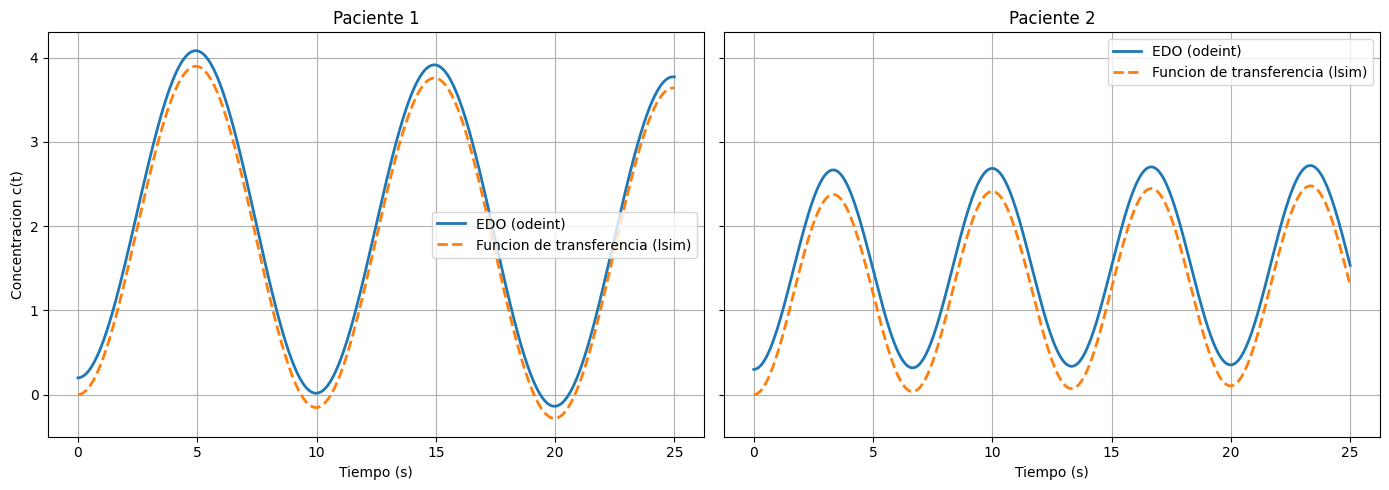

,Tiempo (s),Paciente 1 - EDO,Paciente 1 - FT,Paciente 1 - Dif. abs.,Paciente 2 - EDO,Paciente 2 - FT,Paciente 2 - Dif. abs.
0,0.000000,0.200000,0.000000,0.200000,0.300000,0.000000,0.300000
1,2.775925,2.527263,2.336294,0.190968,2.511734,2.219331,0.292403
2,5.551851,3.935728,3.753391,0.182337,0.900621,0.615646,0.284974
3,8.327776,1.002135,0.828049,0.174086,1.506215,1.228469,0.277746
4,11.103701,0.490828,0.324614,0.166215,2.098351,1.827650,0.270701
5,13.887963,3.497464,3.338780,0.158684,0.501014,0.237211,0.263803
6,16.663888,2.853251,2.701743,0.151508,2.703614,2.446494,0.257120
7,19.439813,-0.024417,-0.169068,0.144651,0.508503,0.257919,0.250584
8,22.215739,1.517093,1.378978,0.138115,2.130169,1.885935,0.244234
9,25.000000,3.771397,3.639540,0.131857,1.535464,1.297450,0.238014


In [6]:
def resolver_ode(D_func, ta, te, td, c0, t):
    def sistema(y, t):
        c, dc = y
        ddc = (D_func(t) - te * dc - c / td) / ta
        return [dc, ddc]
    sol = odeint(sistema, [c0, 0], t)
    return sol[:, 0]

def resolver_tf(D_func, ta, te, td, t):
    num = [1]
    den = [ta, te, 1 / td]
    sist = signal.TransferFunction(num, den)
    _, y, _ = signal.lsim(sist, U=D_func(t), T=t)
    return y

# Paciente 1
c_ode_1 = resolver_ode(D1, ta1, te1, td1, c0_1, t)
c_tf_1 = resolver_tf(D1, ta1, te1, td1, t)

# Paciente 2
c_ode_2 = resolver_ode(D2, ta2, te2, td2, c0_2, t)
c_tf_2 = resolver_tf(D2, ta2, te2, td2, t)

fig, axs = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
axs[0].plot(t, c_ode_1, label='EDO (odeint)', linewidth=2)
axs[0].plot(t, c_tf_1, '--', label='Funcion de transferencia (lsim)', linewidth=2)
axs[0].set_title('Paciente 1')
axs[0].set_xlabel('Tiempo (s)'); axs[0].set_ylabel('Concentracion c(t)')
axs[0].legend(); axs[0].grid(True)

axs[1].plot(t, c_ode_2, label='EDO (odeint)', linewidth=2)
axs[1].plot(t, c_tf_2, '--', label='Funcion de transferencia (lsim)', linewidth=2)
axs[1].set_title('Paciente 2')
axs[1].set_xlabel('Tiempo (s)')
axs[1].legend(); axs[1].grid(True)

plt.tight_layout()
plt.show()

# Tabla comparativa
idx = np.linspace(0, len(t) - 1, 10).astype(int)
tabla = pd.DataFrame({
    'Tiempo (s)': t[idx],
    'Paciente 1 - EDO': c_ode_1[idx],
    'Paciente 1 - FT': c_tf_1[idx],
    'Paciente 1 - Dif. abs.': np.abs(c_ode_1[idx] - c_tf_1[idx]),
    'Paciente 2 - EDO': c_ode_2[idx],
    'Paciente 2 - FT': c_tf_2[idx],
    'Paciente 2 - Dif. abs.': np.abs(c_ode_2[idx] - c_tf_2[idx]),
})
tabla